# 02 최소 EDA

목적: `decisions.md`의 D1(가진 피크), D3(MA 적용), D4(대역 경계)를 숫자로 판단할 근거 만들기.

비교 지표 (두 집단 차이를 단순하게 보기 위함)
- **중앙값 비** = 고장 중앙값 / 정상 중앙값
- **고장 초과율** = 정상 95번째 백분위수를 넘는 고장 파일 비율 (정상만 보고 정한 선을 고장이 얼마나 넘는가)

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch
from scipy.stats import kurtosis

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data import load_dataset

FS = 25_000
X, y, names = load_dataset(ROOT / "data" / "TeamProject_train_변경")
Xd = X - X.mean(axis=1, keepdims=True)  # 평균 제거 (필수 전처리)

def compare(values):
    """정상(0)·고장(1) 차이 요약: 중앙값, 중앙값 비, 고장 초과율"""
    v0, v1 = values[y == 0], values[y == 1]
    p95 = np.percentile(v0, 95)
    return {
        "정상 중앙값": np.median(v0),
        "고장 중앙값": np.median(v1),
        "중앙값 비": np.median(v1) / np.median(v0),
        "고장 초과율": (v1 > p95).mean(),
    }

## 1. 파형 한 쌍 (각 클래스에서 표준편차가 중앙값에 가장 가까운 파일)

대표 파일: nor_006 abn_001


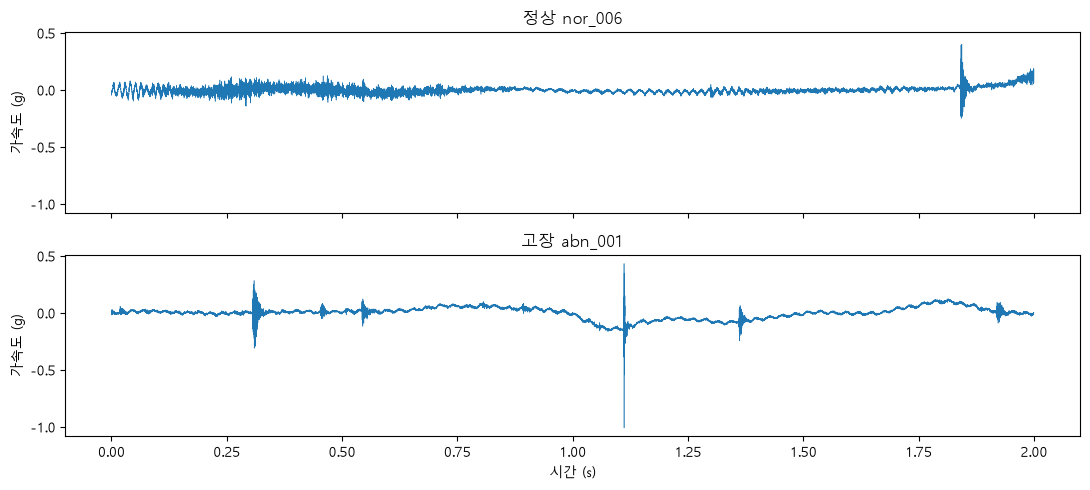

In [2]:
std = Xd.std(axis=1)
def typical(label):
    idx = np.where(y == label)[0]
    return idx[np.argmin(np.abs(std[idx] - np.median(std[idx])))]

i0, i1 = typical(0), typical(1)
print("대표 파일:", names[i0], names[i1])

t = np.arange(X.shape[1]) / FS
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True, sharey=True)
for ax, i, title in [(axes[0], i0, "정상"), (axes[1], i1, "고장")]:
    ax.plot(t, Xd[i], lw=0.4)
    ax.set_title(f"{title} {names[i]}")
    ax.set_ylabel("가속도 (g)")
axes[1].set_xlabel("시간 (s)")
plt.tight_layout()
plt.show()

## 2. 클래스별 평균 스펙트럼 (Welch)

Welch: 신호를 겹치는 조각으로 나눠 조각마다 FFT 후 평균 → 잡음이 줄어든 파워 스펙트럼(PSD). `nperseg=4096`이면 주파수 간격 약 6.1 Hz

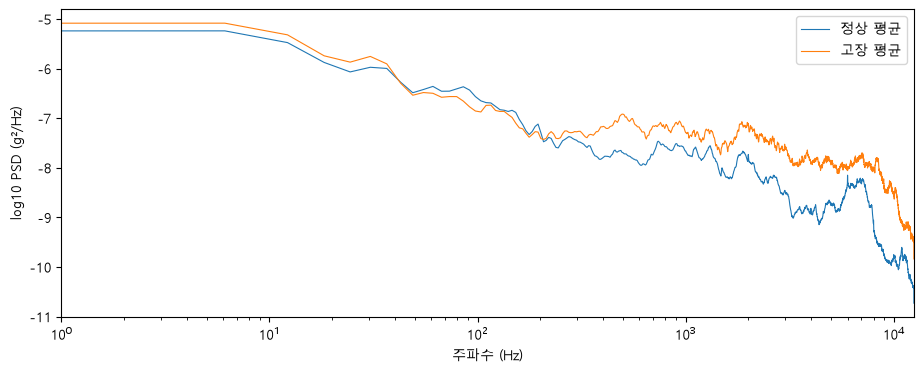

In [3]:
f, P = welch(Xd, fs=FS, nperseg=4096, axis=1)  # P: (150, 주파수 수)
logP = np.log10(P + 1e-20)

fig, ax = plt.subplots(figsize=(11, 4))
for label, name in [(0, "정상 평균"), (1, "고장 평균")]:
    ax.plot(f, logP[y == label].mean(axis=0), lw=0.8, label=name)
ax.set_xscale("log")
ax.set_xlim(1, FS / 2)
ax.set_xlabel("주파수 (Hz)")
ax.set_ylabel("log10 PSD (g²/Hz)")
ax.legend()
plt.show()

## 3. 대역별 에너지 비교 (D4)

노션 물리 분할 예시(0–2k, 2k–5k, 5k–12.5k)와 더 잘게 나눈 대역을 함께 본다

In [4]:
def band_power(lo, hi):
    m = (f >= lo) & (f < hi)
    return P[:, m].sum(axis=1)

edges = [0, 50, 200, 500, 1000, 2000, 3000, 5000, 8000, 12500]
rows = []
for lo, hi in list(zip(edges[:-1], edges[1:])) + [(0, 2000), (2000, 5000), (5000, 12500)]:
    bp = band_power(lo, hi)
    ratio = bp / P.sum(axis=1)
    rows.append({"대역(Hz)": f"{lo}-{hi}", **{f"절대 {k}": v for k, v in compare(bp).items() if k in ("중앙값 비", "고장 초과율")},
                 **{f"비율 {k}": v for k, v in compare(ratio).items() if k in ("중앙값 비", "고장 초과율")}})
band_df = pd.DataFrame(rows)
print(band_df.round(2).to_string(index=False))

    대역(Hz)  절대 중앙값 비  절대 고장 초과율  비율 중앙값 비  비율 고장 초과율
      0-50      1.45       0.10      0.80       0.07
    50-200      0.35       0.10      0.14       0.00
   200-500      3.74       0.13      0.53       0.07
  500-1000      3.30       0.23      1.17       0.00
 1000-2000      2.23       0.23      1.27       0.07
 2000-3000      5.10       0.37      1.52       0.33
 3000-5000     18.83       0.33      6.04       0.27
 5000-8000      2.82       0.27      1.05       0.07
8000-12500     27.22       0.47     31.21       0.60
    0-2000      1.97       0.13      0.77       0.03
 2000-5000      7.62       0.40      3.44       0.40
5000-12500      5.00       0.37      1.79       0.17


## 4. 파일별 최대 피크 주파수 (D1)

정현파 가진이라면 모든 파일에서 같은 주파수에 큰 피크가 있어야 한다

In [5]:
peak_f = f[P.argmax(axis=1)]
print("전체 대역 최대 피크 주파수, 상위 빈도 (Hz: 파일 수)")
for label, name in [(0, "정상"), (1, "고장")]:
    vc = pd.Series(np.round(peak_f[y == label], 1)).value_counts().head(6)
    print(f"  {name}:", dict(vc))

# 20 Hz 이상만 보면 (아주 낮은 주파수 드리프트 제외)
m = f >= 20
peak_f20 = f[m][P[:, m].argmax(axis=1)]
print("20 Hz 이상 최대 피크 주파수 사분위 (정상 / 고장):")
print("  정상", np.percentile(peak_f20[y == 0], [25, 50, 75]).round(1))
print("  고장", np.percentile(peak_f20[y == 1], [25, 50, 75]).round(1))

전체 대역 최대 피크 주파수, 상위 빈도 (Hz: 파일 수)
  정상: {6.1: np.int64(67), 12.2: np.int64(12), 30.5: np.int64(11), 36.6: np.int64(9), 61.0: np.int64(3), 18.3: np.int64(2)}
  고장: {6.1: np.int64(16), 12.2: np.int64(5), 30.5: np.int64(2), 1153.6: np.int64(2), 1904.3: np.int64(1), 1159.7: np.int64(1)}
20 Hz 이상 최대 피크 주파수 사분위 (정상 / 고장):
  정상 [30.5 48.8 97.7]
  고장 [  30.5   36.6 1153.6]


## 5. 평균제거 vs MA 신호 (D3)

MA는 저역통과라 짧은 충격을 뭉갤 수 있다. 첨도·Peak로 정상/고장 구분이 MA 후에 약해지는지 본다

In [6]:
def moving_average(Z, M):
    k = np.ones(M) / M
    return np.apply_along_axis(lambda s: np.convolve(s, k, mode="same"), 1, Z)

rows = []
for M in [1, 5, 10, 20]:
    Z = Xd if M == 1 else moving_average(Xd, M)
    for feat, values in [("첨도", kurtosis(Z, axis=1, fisher=False)),
                         ("Peak", np.abs(Z).max(axis=1)),
                         ("RMS", Z.std(axis=1))]:
        rows.append({"MA 창 M": "없음" if M == 1 else M, "피처": feat, **compare(values)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

MA 창 M   피처  정상 중앙값  고장 중앙값  중앙값 비  고장 초과율
    없음   첨도   4.614  19.537  4.234   0.200
    없음 Peak   0.222   0.951  4.285   0.367
    없음  RMS   0.029   0.051  1.739   0.233
     5   첨도   3.558   8.100  2.276   0.267
     5 Peak   0.135   0.428  3.168   0.367
     5  RMS   0.027   0.042  1.571   0.133
    10   첨도   3.306   6.284  1.901   0.267
    10 Peak   0.121   0.241  1.987   0.300
    10  RMS   0.026   0.037  1.457   0.100
    20   첨도   3.334   4.793  1.438   0.267
    20 Peak   0.103   0.220  2.129   0.200
    20  RMS   0.025   0.032  1.306   0.133
